Original Dataset Shape: (1998, 24)


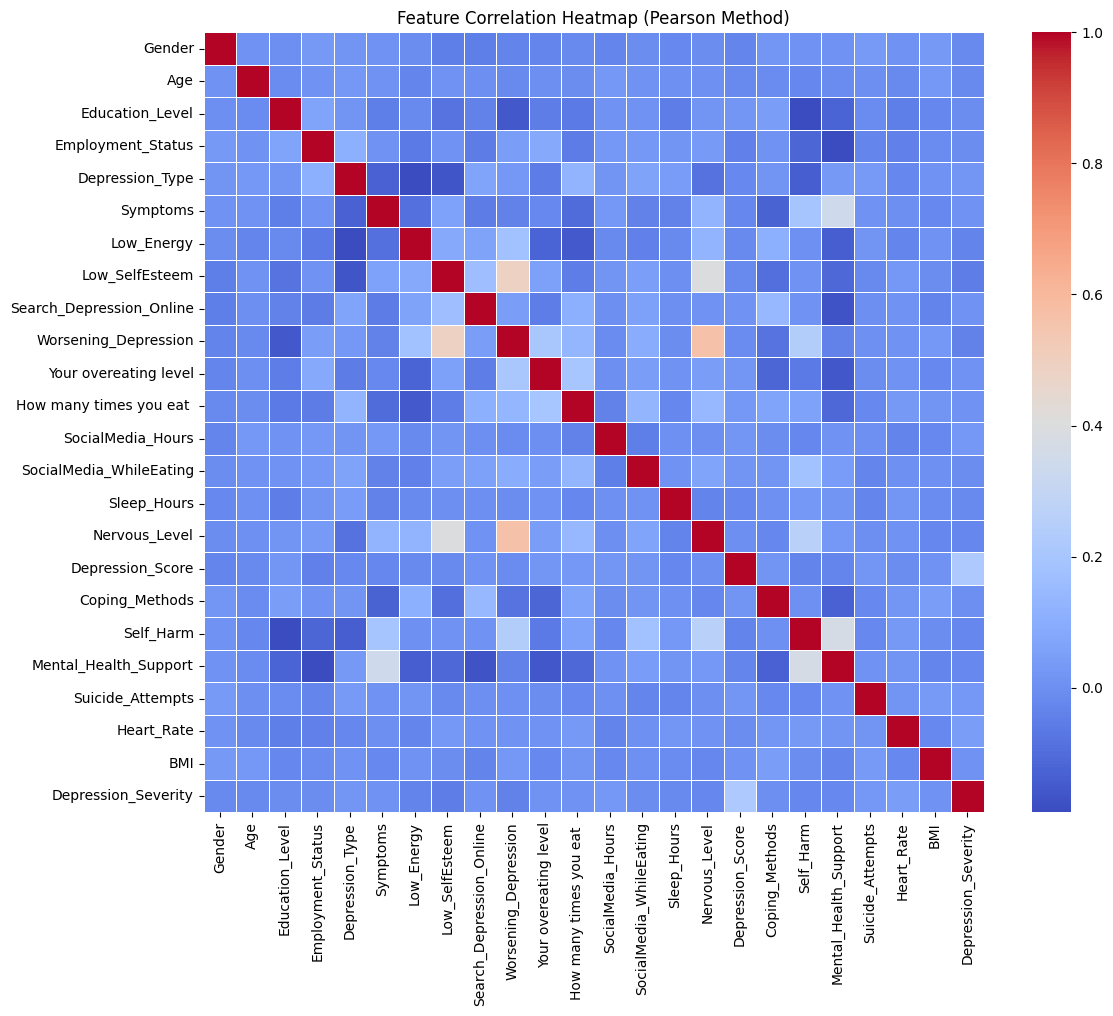


No highly correlated feature pairs found (>|0.85|).

Class Distribution:
 Depression_Severity
3    667
0    369
1    328
4    324
2    310
Name: count, dtype: int64

Gender Distribution:
 Gender
1    1027
0     971
Name: count, dtype: int64

Age Summary:
 count    1998.000000
mean       24.261762
std         7.928578
min        10.000000
25%        25.000000
50%        25.000000
75%        25.000000
max        35.000000
Name: Age, dtype: float64
Best RF Params: {'model__max_depth': 8, 'model__max_features': 'sqrt', 'model__min_samples_leaf': 4, 'model__min_samples_split': 10, 'model__n_estimators': 40}
Best SVM Params: {'model__C': 1, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Random Forest Accuracy: 0.964
Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.93      0.95        92
           1       0.88      0.94      0.91        82
           2       0.96      0.91      0.93        78
           3       1.00      1.00  

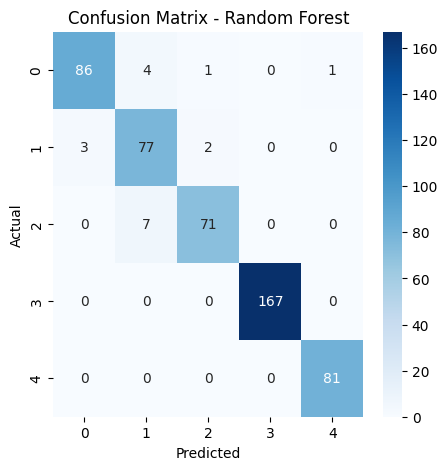

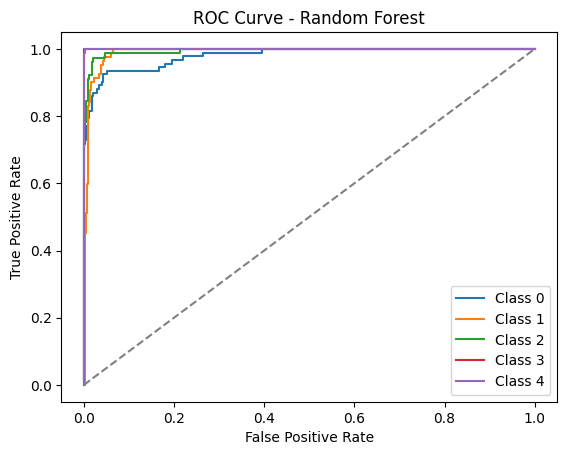


SVM Accuracy: 0.726
Classification Report:
               precision    recall  f1-score   support

           0       0.62      0.59      0.60        92
           1       0.56      0.57      0.57        82
           2       0.58      0.58      0.58        78
           3       0.91      0.89      0.90       167
           4       0.77      0.84      0.80        81

    accuracy                           0.73       500
   macro avg       0.69      0.69      0.69       500
weighted avg       0.73      0.73      0.73       500



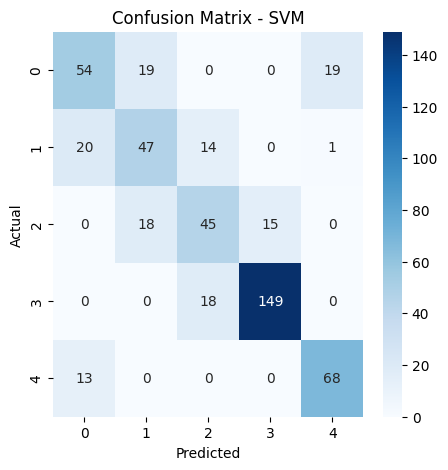

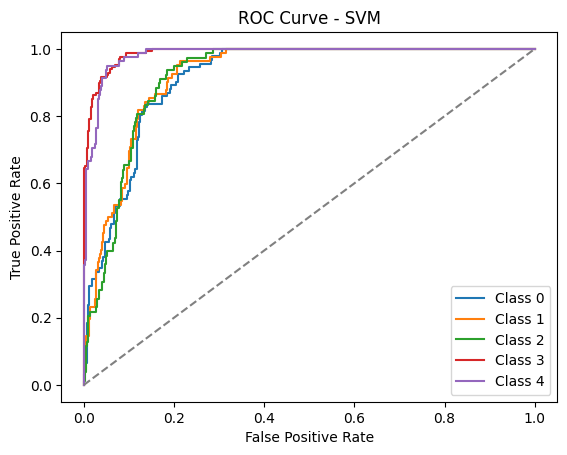


Logistic Regression Accuracy: 0.926
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.92      0.90        92
           1       0.87      0.89      0.88        82
           2       0.90      0.85      0.87        78
           3       0.98      0.96      0.97       167
           4       0.95      0.96      0.96        81

    accuracy                           0.93       500
   macro avg       0.92      0.92      0.92       500
weighted avg       0.93      0.93      0.93       500



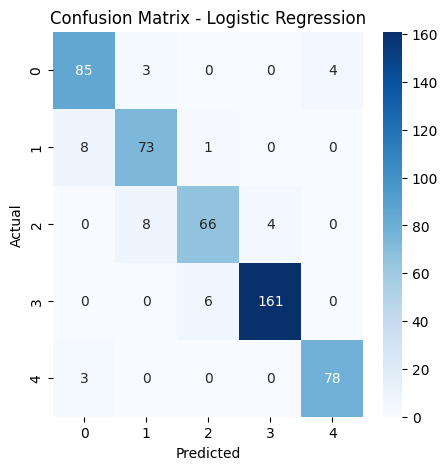

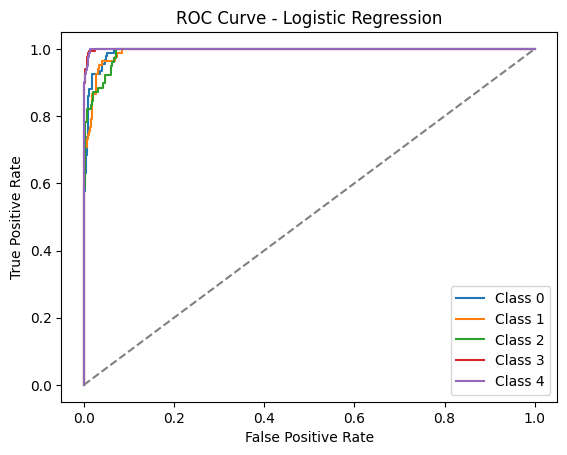


Cross-Validation Results:
                  Model  CV Accuracy
0        Random Forest     0.964467
1                  SVM     0.779296
2  Logistic Regression     0.956469


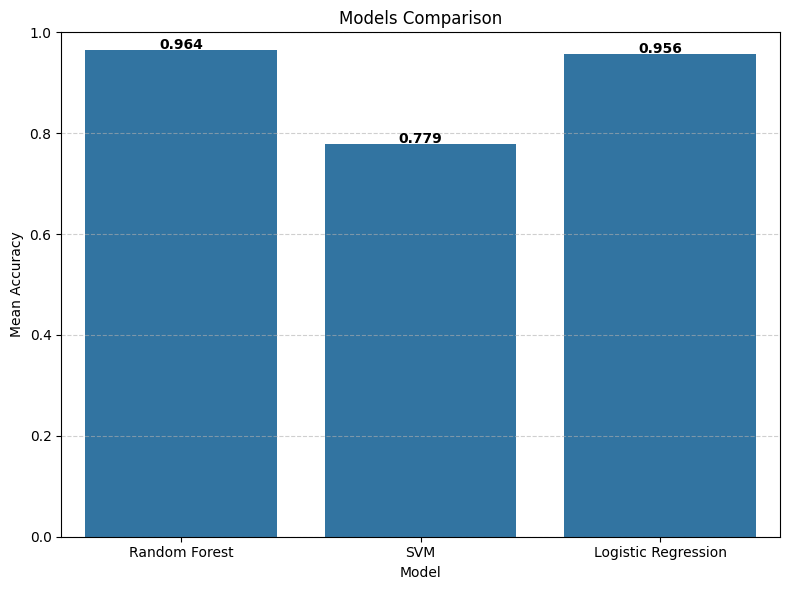

Psychological Only Accuracy: 0.330
Demographic Only Accuracy: 0.308
Physiological Only Accuracy: 0.330
Multi-Modal Accuracy: 0.330


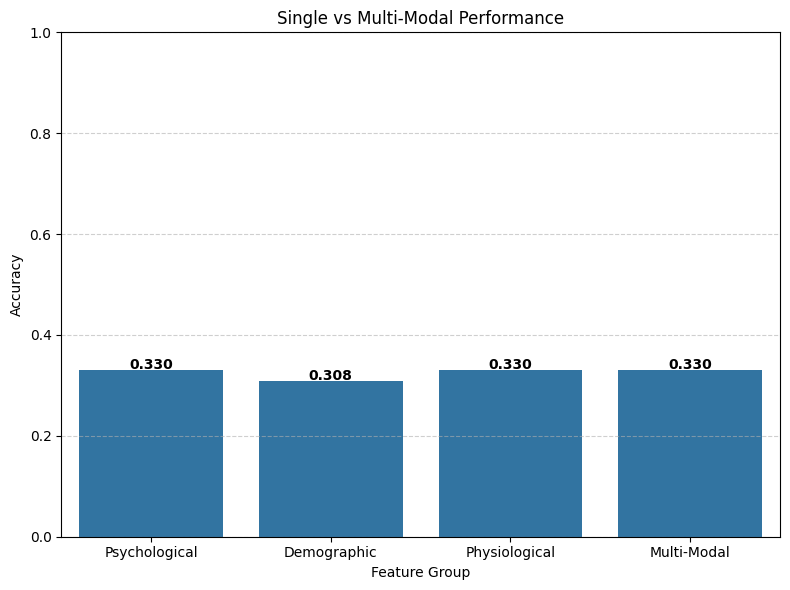

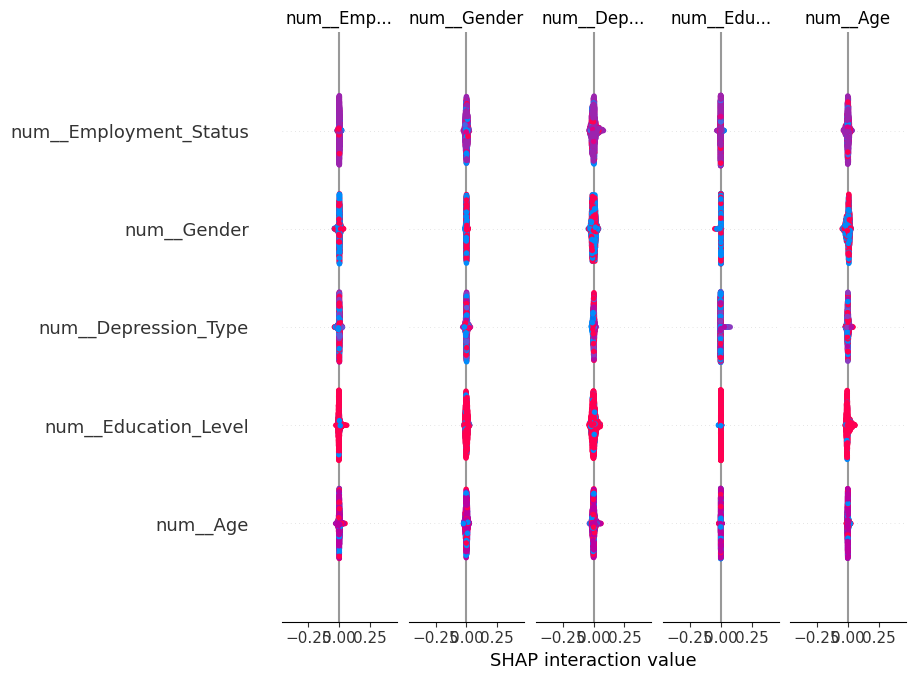


LIME Explanation: [('num__Depression_Type <= -1.23', -0.04141936939341866), ('num__Education_Level <= 0.27', -0.038684146983002134), ('num__How many times you eat  <= -0.50', 0.03741065663371183), ('num__Symptoms <= -0.41', -0.03258945602545109), ('num__Employment_Status <= -0.09', -0.024550296010102786), ('num__Age <= 0.11', 0.024058475802040995), ('-0.07 < num__Depression_Score <= 0.90', -0.016978086941285903), ('num__Coping_Methods > 0.76', 0.01622477547465554), ('0.06 < num__Heart_Rate <= 0.91', 0.01565952849099683), ('num__Self_Harm <= -0.34', -0.015269273538328035)]

--- Gender Subgroup Accuracy (RF) ---
Gender 0 Accuracy: 0.968
Gender 1 Accuracy: 0.960

--- Age Group Subgroup Accuracy (RF) ---
Age Group (0, 25] Accuracy: 0.967
Age Group (25, 40] Accuracy: 0.955


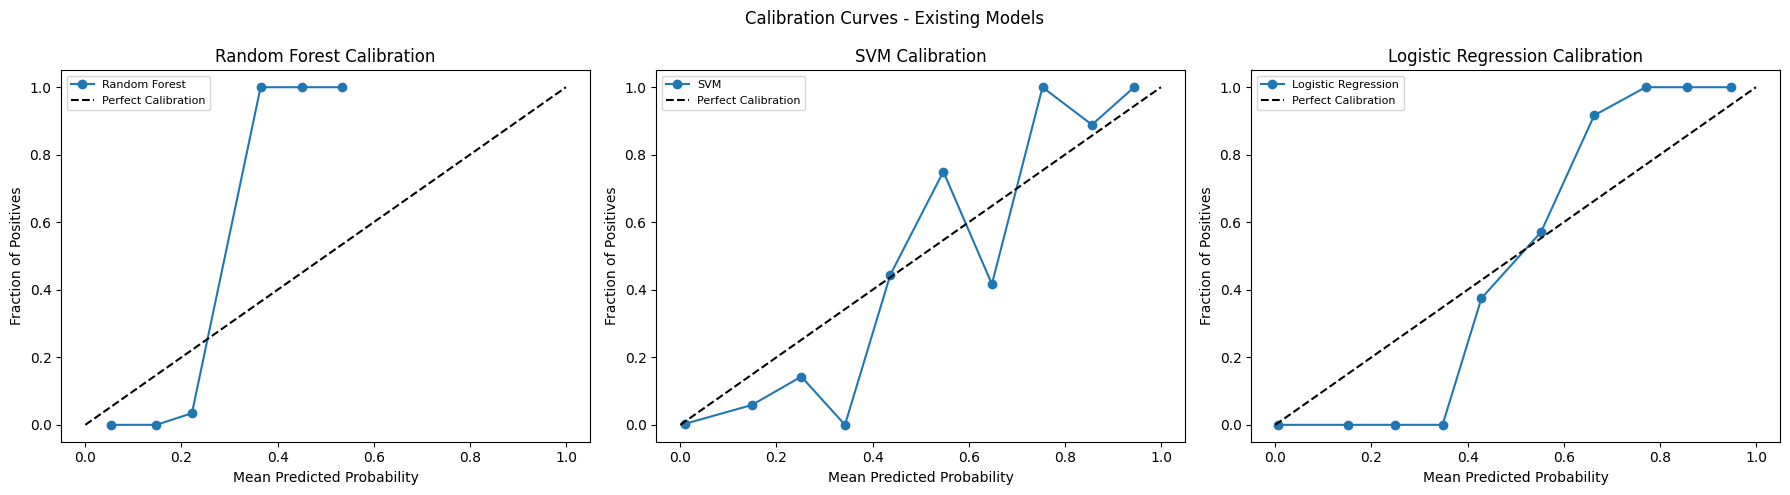


Robustness Test (Random Forest)
Original RF Accuracy: 0.964
Noisy RF Accuracy: 0.966


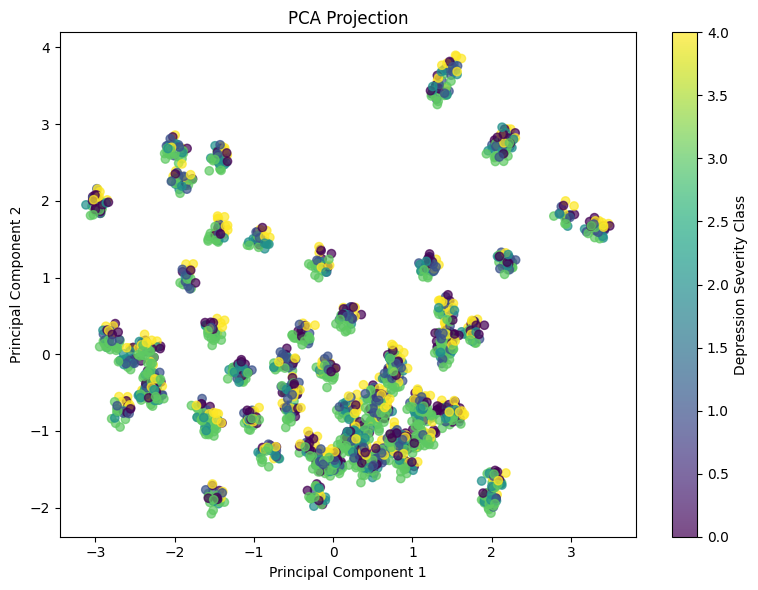

PCA explained variance ratio: [0.09813457 0.08020105]

Intersectional Fairness Analysis (RF):
 Gender AgeGroup   N  Accuracy  Sensitivity (Macro Recall)
      0      <25 192    0.9688                      0.9614
      0    25-40  57    0.9649                      0.9429
      1      <25 198    0.9646                      0.9592
      1    25-40  53    0.9434                      0.9250

Equal Opportunity Difference (EOD) - Random Forest: 0.0000
 Gender AgeGroup   N  TPR
      0      <25 192  1.0
      0    25-40  57  1.0
      1      <25 198  1.0
      1    25-40  53  1.0

Bootstrap 95% CI for Random Forest test accuracy: 0.9642 (0.9480, 0.9800)

Temporal Validation
Important: meaningful only if dataset rows are already ordered by time.
Temporal Accuracy: 0.9533
Temporal Drift: 0.0107
XGBoost — research implementation
Train Acc: 0.942
Test Acc: 0.925
CV Acc: 0.899 (+/- 0.041)

XGBoost Results Table:
  Model Test Acc CV Acc AUC-ROC Brier
XGBoost    0.925  0.899   0.993 0.024


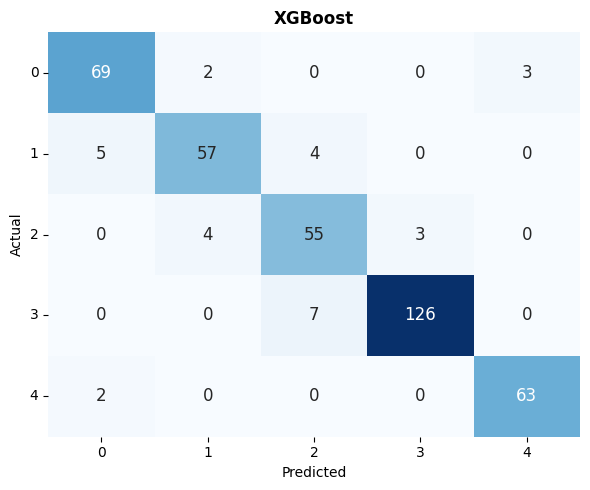

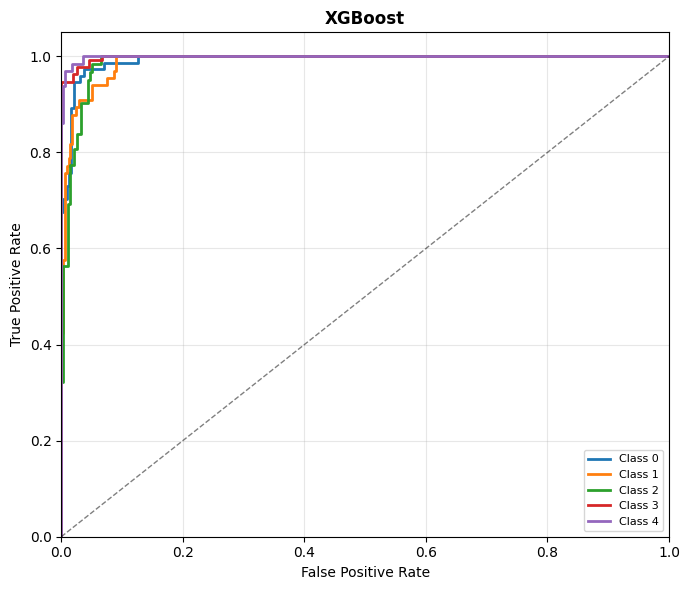

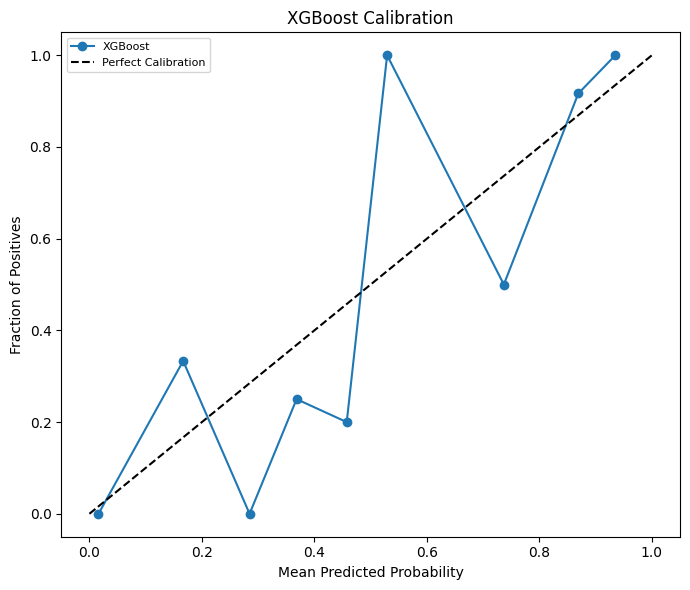


Research-matched model comparison (same test split):
              Model Train Acc Test Acc CV Acc AUC-ROC Brier
      Random Forest     0.942    0.905  0.842   0.982 0.086
            XGBoost     0.942    0.925  0.899   0.993 0.024
Logistic Regression     0.833    0.787  0.739   0.965 0.071
                SVM     0.815    0.660  0.602   0.921 0.082


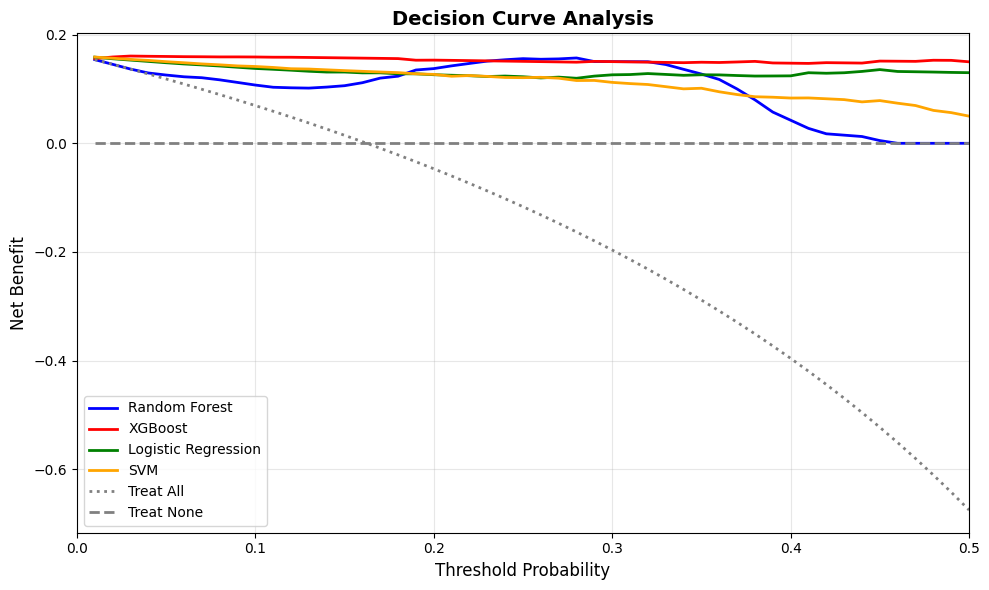


Net Benefit at key thresholds:
------------------------------------------------------------
Threshold   Random For  XGBoost     Logistic R  SVM         Treat All 
------------------------------------------------------------
0.01        0.1540        0.1558        0.1586        0.1588        0.1540
0.11        0.1032        0.1585        0.1362        0.1396        0.0590
0.21        0.1426        0.1527        0.1253        0.1234        -0.0601
0.31        0.1503        0.1499        0.1266        0.1099        -0.2138
0.41        0.0275        0.1471        0.1299        0.0835        -0.4195

Mean Net Benefit by model:
Random Forest: 0.1023
XGBoost: 0.1531
Logistic Regression: 0.1316
SVM: 0.1140


In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, roc_auc_score, roc_curve, auc
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from lime.lime_tabular import LimeTabularExplainer
from sklearn.preprocessing import label_binarize
import shap
import joblib
import warnings
warnings.filterwarnings('ignore')

# Load dataset

data_path = "/content/drive/MyDrive/myapp/Mental_Health_with_Severity.csv"
data = pd.read_csv(data_path)
print("Original Dataset Shape:", data.shape)

# Encode target labels
target_col = "Depression_Severity"
le = LabelEncoder()
data[target_col] = le.fit_transform(data[target_col])

X = data.drop(target_col, axis=1)
y = data[target_col]

# Check feature correlations

# Select numeric features
corr_features = data.select_dtypes(include=[np.number])

# Calculate Pearson correlations
corr_matrix = corr_features.corr(method='pearson')

# Plot correlation heatmap
plt.figure(figsize=(12,10))
sns.heatmap(
    corr_matrix,
    cmap='coolwarm',
    annot=False,
    square=True,
    linewidths=0.5
)

plt.title("Feature Correlation Heatmap (Pearson Method)")
plt.tight_layout()
plt.show()

# Print highly correlated feature pairs
threshold = 0.85
high_corr = []

for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > threshold:
            high_corr.append((
                corr_matrix.columns[i],
                corr_matrix.columns[j],
                corr_matrix.iloc[i, j]
            ))

if high_corr:
    print("\nHighly Correlated Feature Pairs (>|0.85|):")
    for f1, f2, val in high_corr:
        print(f"{f1} - {f2}: {val:.2f}")
else:
    print("\nNo highly correlated feature pairs found (>|0.85|).")

# Summarize dataset and demographics

print("\nClass Distribution:\n", y.value_counts())
if 'Gender' in X.columns:
    print("\nGender Distribution:\n", X['Gender'].value_counts())
if 'Age' in X.columns:
    print("\nAge Summary:\n", X['Age'].describe())

# Define feature groups

psychological_features = [
    'Depression_Type', 'Symptoms', 'Low_Energy',
    'Low_SelfEsteem', 'Worsening_Depression',
    'Nervous_Level', 'Coping_Methods', 'Self_Harm'
]

demographic_features = [
    'Gender', 'Age', 'Education_Level', 'Employment_Status'
]

physiological_features = [
    'Heart_Rate', 'BMI', 'Sleep_Hours'
]

all_features = psychological_features + demographic_features + physiological_features

num_features = X.select_dtypes(include=[np.number]).columns.tolist()
cat_features = X.select_dtypes(exclude=[np.number]).columns.tolist()

# Define preprocessing steps
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), num_features),
    ('cat', OneHotEncoder(drop='first', sparse_output=False), cat_features)
])

# Split training and test data

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=30, stratify=y
)

# Configure cross-validation

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=30)

# Define and tune model pipelines

# Random Forest model
rf_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', RandomForestClassifier(random_state=30))
])

rf_params = {
    'model__n_estimators': [20, 40],
    'model__max_depth': [5, 8],
    'model__min_samples_split': [5, 10],
    'model__min_samples_leaf': [2, 4],
    'model__max_features': ['sqrt']
}

rf_grid = GridSearchCV(rf_pipeline, rf_params, cv=cv, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)
rf_best = rf_grid.best_estimator_
print("Best RF Params:", rf_grid.best_params_)

# Support Vector Machine model
svm_pipeline = Pipeline([
    ('preprocess', preprocessor),
    ('model', SVC(probability=True, random_state=30))
])

svm_params = {
    'model__C': [0.1, 0.5, 1],
    'model__gamma': ['scale'],
    'model__kernel': ['rbf']
}

svm_grid = GridSearchCV(svm_pipeline, svm_params, cv=cv, scoring='accuracy', n_jobs=-1)
svm_grid.fit(X_train, y_train)
svm_best = svm_grid.best_estimator_
print("Best SVM Params:", svm_grid.best_params_)

# Logistic Regression baseline
baseline = Pipeline([
    ('preprocess', preprocessor),
    ('model', LogisticRegression(max_iter=200))
])
baseline.fit(X_train, y_train)

# Define model evaluation

def evaluate_model(model, X_test, y_test, name):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    print(f"\n{name} Accuracy: {acc:.3f}")
    print("Classification Report:\n", classification_report(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5,5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.show()

    # Calculate ROC-AUC
    if hasattr(model.named_steps['model'], "predict_proba"):
        y_prob = model.predict_proba(X_test)
        classes = np.unique(y_test)
        y_test_bin = label_binarize(y_test, classes=classes)
        plt.figure()
        for i in range(len(classes)):
            fpr, tpr, _ = roc_curve(y_test_bin[:,i], y_prob[:,i])
            plt.plot(fpr, tpr, label=f'Class {i}')
        plt.plot([0,1], [0,1], '--', color='gray')
        plt.title(f'ROC Curve - {name}')
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend(loc='lower right')
        plt.show()
    return acc

# Evaluate models

acc_rf = evaluate_model(rf_best, X_test, y_test, "Random Forest")
acc_svm = evaluate_model(svm_best, X_test, y_test, "SVM")
acc_base = evaluate_model(baseline, X_test, y_test, "Logistic Regression")

# Calculate cross-validation scores

rf_cv = cross_val_score(rf_best, X, y, cv=cv, scoring='accuracy')
svm_cv = cross_val_score(svm_best, X, y, cv=cv, scoring='accuracy')
base_cv = cross_val_score(baseline, X, y, cv=cv, scoring='accuracy')

# Display cross-validation results
cv_results = pd.DataFrame({
    "Model": ["Random Forest","SVM","Logistic Regression"],
    "CV Accuracy": [rf_cv.mean(), svm_cv.mean(), base_cv.mean()]
})
print("\nCross-Validation Results:\n", cv_results)

# Plot model comparison
plt.figure(figsize=(8,6))
sns.barplot(x="Model", y="CV Accuracy", data=cv_results)
for i, v in enumerate(cv_results["CV Accuracy"]):
    plt.text(i, v+0.002, f"{v:.3f}", ha='center', fontweight='bold')
plt.ylim(0,1)
plt.title("Models Comparison")
plt.ylabel("Mean Accuracy")
plt.xlabel("Model")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Compare single- and multimodal accuracy

def modality_accuracy(features, name):
    X_mod = X[features]
    X_tr, X_te, y_tr, y_te = train_test_split(X_mod, y, test_size=0.25, stratify=y, random_state=42)
    pipe = Pipeline([
        ('scaler', StandardScaler()),
        ('model', RandomForestClassifier(n_estimators=100, max_depth=6, random_state=42))
    ])
    pipe.fit(X_tr, y_tr)
    y_pred = pipe.predict(X_te)
    acc = accuracy_score(y_te, y_pred)
    print(f"{name} Accuracy: {acc:.3f}")
    return acc

acc_psy = modality_accuracy(psychological_features, "Psychological Only")
acc_demo = modality_accuracy(demographic_features, "Demographic Only")
acc_phy = modality_accuracy(physiological_features, "Physiological Only")
acc_all = modality_accuracy(all_features, "Multi-Modal")

# Plot single- and multimodal accuracy
mod_results = pd.DataFrame({
    "Modality": ["Psychological","Demographic","Physiological","Multi-Modal"],
    "Accuracy": [acc_psy, acc_demo, acc_phy, acc_all]
})
plt.figure(figsize=(8,6))
sns.barplot(x="Modality", y="Accuracy", data=mod_results)
for i, v in enumerate(mod_results["Accuracy"]):
    plt.text(i, v+0.002, f"{v:.3f}", ha='center', fontweight='bold')
plt.ylim(0,1)
plt.title("Single vs Multi-Modal Performance")
plt.ylabel("Accuracy")
plt.xlabel("Feature Group")
plt.grid(axis='y', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

# Explain Random Forest features with SHAP

X_train_trans = rf_best.named_steps['preprocess'].fit_transform(X_train)
feature_names = rf_best.named_steps['preprocess'].get_feature_names_out()
explainer = shap.TreeExplainer(rf_best.named_steps['model'])
shap_values = explainer.shap_values(X_train_trans)
shap.summary_plot(shap_values, X_train_trans, feature_names=feature_names)

# Explain SVM predictions with LIME

X_train_lime = svm_best.named_steps['preprocess'].fit_transform(X_train)
X_test_lime = svm_best.named_steps['preprocess'].transform(X_test)
class_names = le.classes_
lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime,
    feature_names=feature_names,
    class_names=class_names,
    mode='classification'
)
i = 0
exp = lime_explainer.explain_instance(
    X_test_lime[i],
    svm_best.named_steps['model'].predict_proba,
    num_features=10
)
exp.show_in_notebook()
print("\nLIME Explanation:", exp.as_list())

# Analyze performance by gender and age

print("\n--- Gender Subgroup Accuracy (RF) ---")
if 'Gender' in X_test.columns:
    for g in X_test['Gender'].unique():
        idx = X_test['Gender'] == g
        acc = accuracy_score(y_test[idx], rf_best.predict(X_test[idx]))
        print(f"Gender {g} Accuracy: {acc:.3f}")

if 'Age' in X_test.columns:
    bins = [0,25,40,60,100]
    X_test['AgeGroup'] = pd.cut(X_test['Age'], bins)
    print("\n--- Age Group Subgroup Accuracy (RF) ---")
    for grp in X_test['AgeGroup'].unique():
        idx = X_test['AgeGroup'] == grp
        acc = accuracy_score(y_test[idx], rf_best.predict(X_test[idx]))
        print(f"Age Group {grp} Accuracy: {acc:.3f}")

# Additional research analyses

from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.calibration import calibration_curve
from sklearn.metrics import recall_score, roc_auc_score, roc_curve
from sklearn.preprocessing import label_binarize

additional_X_test = X_test.drop(columns=["AgeGroup"], errors="ignore").copy()
additional_y_test = y_test.copy()
additional_classes = np.sort(np.unique(y))
additional_n_classes = len(additional_classes)

additional_models = {
    "Random Forest": rf_best,
    "SVM": svm_best,
    "Logistic Regression": baseline,
}

additional_predictions = {
    name: model.predict(additional_X_test)
    for name, model in additional_models.items()
}
additional_probabilities = {
    name: model.predict_proba(additional_X_test)
    for name, model in additional_models.items()
    if hasattr(model, "predict_proba")
}

# Plot calibration curves for existing models

additional_positive_class = 4 if 4 in additional_classes else additional_classes[-1]
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes = axes.flatten()
for additional_i, (additional_name, additional_model) in enumerate(additional_models.items()):
    additional_ax = axes[additional_i]
    additional_model_classes = list(additional_model.classes_)
    if additional_positive_class not in additional_model_classes:
        additional_ax.set_title(f"{additional_name} Calibration (class unavailable)")
        additional_ax.axis("off")
        continue
    additional_class_index = additional_model_classes.index(additional_positive_class)
    additional_prob_positive = additional_probabilities[additional_name][:, additional_class_index]
    additional_y_positive = (additional_y_test.to_numpy() == additional_positive_class).astype(int)
    additional_fraction, additional_mean = calibration_curve(
        additional_y_positive, additional_prob_positive,
        n_bins=10, strategy="uniform"
    )
    additional_ax.plot(additional_mean, additional_fraction, marker="o", label=additional_name)
    additional_ax.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
    additional_ax.set_title(f"{additional_name} Calibration")
    additional_ax.set_xlabel("Mean Predicted Probability")
    additional_ax.set_ylabel("Fraction of Positives")
    additional_ax.legend(loc="best", fontsize=8)
plt.suptitle("Calibration Curves - Existing Models")
plt.tight_layout()
plt.show()

# Test Random Forest robustness to noise

additional_noisy_X_test = additional_X_test.copy()
additional_noise_columns = [
    col for col in ["Heart_Rate", "BMI", "Sleep_Hours"]
    if col in additional_noisy_X_test.columns
    and pd.api.types.is_numeric_dtype(additional_noisy_X_test[col])
]
if additional_noise_columns:
    np.random.seed(42)
    for additional_col in additional_noise_columns:
        additional_noisy_X_test[additional_col] = (
            additional_noisy_X_test[additional_col]
            + np.random.normal(0, 2, len(additional_noisy_X_test))
        )
    print("\nRobustness Test (Random Forest)")
    print("Original RF Accuracy:", round(
        accuracy_score(additional_y_test, rf_best.predict(additional_X_test)), 4
    ))
    print("Noisy RF Accuracy:", round(
        accuracy_score(additional_y_test, rf_best.predict(additional_noisy_X_test)), 4
    ))
else:
    print("\nRobustness Test skipped: none of Heart_Rate, BMI, Sleep_Hours were available.")

# Plot PCA projection

try:
    additional_pca_preprocessor = clone(preprocessor)
    additional_X_transformed = additional_pca_preprocessor.fit_transform(X.copy())
    additional_pca = PCA(n_components=2, random_state=42)
    additional_X_pca = additional_pca.fit_transform(additional_X_transformed)
    plt.figure(figsize=(8, 6))
    additional_scatter = plt.scatter(
        additional_X_pca[:, 0], additional_X_pca[:, 1],
        c=y.to_numpy(), cmap="viridis", alpha=0.7
    )
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.title("PCA Projection")
    plt.colorbar(additional_scatter, label="Depression Severity Class")
    plt.tight_layout()
    plt.show()
    print("PCA explained variance ratio:", additional_pca.explained_variance_ratio_)
except Exception as additional_error:
    print("\nPCA Projection could not be generated:", additional_error)

# Analyze fairness by gender and age

if "Gender" in additional_X_test.columns and "Age" in additional_X_test.columns:
    additional_fairness_X = additional_X_test[["Gender", "Age"]].copy()
    additional_fairness_X["AgeGroup"] = pd.cut(
        additional_fairness_X["Age"], bins=[0, 25, 40, 100],
        labels=["<25", "25-40", ">40"], include_lowest=True
    )
    additional_fairness_pred = additional_predictions["Random Forest"]
    additional_fairness_rows = []
    for (additional_gender, additional_age_group), additional_group in additional_fairness_X.groupby(
        ["Gender", "AgeGroup"], observed=False
    ):
        if len(additional_group) < 15:
            continue
        additional_mask = (
            (additional_fairness_X["Gender"] == additional_gender)
            & (additional_fairness_X["AgeGroup"] == additional_age_group)
        ).to_numpy()
        additional_true = additional_y_test.to_numpy()[additional_mask]
        additional_pred = additional_fairness_pred[additional_mask]
        additional_fairness_rows.append({
            "Gender": additional_gender,
            "AgeGroup": str(additional_age_group),
            "N": int(np.sum(additional_mask)),
            "Accuracy": accuracy_score(additional_true, additional_pred),
            "Sensitivity (Macro Recall)": recall_score(
                additional_true, additional_pred, average="macro", zero_division=0
            )
        })
    print("\nIntersectional Fairness Analysis (RF):")
    if additional_fairness_rows:
        print(pd.DataFrame(additional_fairness_rows).round(4).to_string(index=False))
    else:
        print("No Gender/Age groups met the minimum size of 15.")
else:
    print("\nIntersectional fairness skipped: Gender and/or Age columns are missing.")

# Calculate equal opportunity difference

additional_test_accuracies = {
    name: accuracy_score(additional_y_test, pred)
    for name, pred in additional_predictions.items()
}
additional_best_name = max(additional_test_accuracies, key=additional_test_accuracies.get)
additional_best_model = additional_models[additional_best_name]
additional_best_pred = additional_predictions[additional_best_name]
if "Gender" in additional_X_test.columns and "Age" in additional_X_test.columns:
    additional_eod_X = additional_X_test[["Gender", "Age"]].copy()
    additional_eod_X["AgeGroup"] = pd.cut(
        additional_eod_X["Age"], bins=[0, 25, 40, 100],
        labels=["<25", "25-40", ">40"], include_lowest=True
    )
    additional_eod_rows = []
    for (additional_gender, additional_age_group), additional_group in additional_eod_X.groupby(
        ["Gender", "AgeGroup"], observed=False
    ):
        if len(additional_group) < 10:
            continue
        additional_mask = (
            (additional_eod_X["Gender"] == additional_gender)
            & (additional_eod_X["AgeGroup"] == additional_age_group)
        ).to_numpy()
        additional_true_binary = (
            additional_y_test.to_numpy()[additional_mask] == additional_positive_class
        )
        additional_pred_binary = (
            additional_best_pred[additional_mask] == additional_positive_class
        )
        additional_positive_count = int(np.sum(additional_true_binary))
        additional_tpr = (
            float(np.sum(additional_true_binary & additional_pred_binary) / additional_positive_count)
            if additional_positive_count else np.nan
        )
        additional_eod_rows.append({
            "Gender": additional_gender,
            "AgeGroup": str(additional_age_group),
            "N": int(np.sum(additional_mask)),
            "TPR": additional_tpr
        })
    additional_eod_table = pd.DataFrame(additional_eod_rows)
    additional_valid_tpr = (
        additional_eod_table["TPR"].dropna()
        if not additional_eod_table.empty else pd.Series(dtype=float)
    )
    additional_eod = (
        float(additional_valid_tpr.max() - additional_valid_tpr.min())
        if len(additional_valid_tpr) >= 2 else np.nan
    )
    print(f"\nEqual Opportunity Difference (EOD) - {additional_best_name}: {additional_eod:.4f}")
    if not additional_eod_table.empty:
        print(additional_eod_table.round(4).to_string(index=False))
else:
    print("\nEOD fairness skipped: Gender and/or Age columns are missing.")

# Estimate test accuracy confidence interval

np.random.seed(42)
additional_bootstrap_accuracies = []
additional_y_array = additional_y_test.to_numpy()
for additional_b in range(1000):
    additional_indices = np.random.choice(
        len(additional_y_array), size=len(additional_y_array), replace=True
    )
    additional_bootstrap_accuracies.append(accuracy_score(
        additional_y_array[additional_indices], additional_best_pred[additional_indices]
    ))
additional_ci_lower, additional_ci_upper = np.percentile(
    additional_bootstrap_accuracies, [2.5, 97.5]
)
print(
    f"\nBootstrap 95% CI for {additional_best_name} test accuracy: "
    f"{np.mean(additional_bootstrap_accuracies):.4f} "
    f"({additional_ci_lower:.4f}, {additional_ci_upper:.4f})"
)

# Temporal validation (requires chronological row order)

print("\nTemporal Validation")
print("Important: meaningful only if dataset rows are already ordered by time.")
try:
    additional_total_rows = len(X)
    additional_train_end = int(additional_total_rows * 0.70)
    additional_test_start = int(additional_total_rows * 0.85)
    if additional_train_end > 0 and additional_test_start < additional_total_rows:
        additional_temporal_model = clone(additional_best_model)
        additional_temporal_model.fit(
            X.iloc[:additional_train_end], y.iloc[:additional_train_end]
        )
        additional_temporal_X = X.iloc[additional_test_start:].copy()
        additional_temporal_y = y.iloc[additional_test_start:].copy()
        additional_temporal_pred = additional_temporal_model.predict(additional_temporal_X)
        additional_temporal_accuracy = accuracy_score(
            additional_temporal_y, additional_temporal_pred
        )
        additional_temporal_drift = abs(
            additional_test_accuracies[additional_best_name] - additional_temporal_accuracy
        )
        print(f"Temporal Accuracy: {additional_temporal_accuracy:.4f}")
        print(f"Temporal Drift: {additional_temporal_drift:.4f}")
    else:
        print("Temporal validation skipped because there are not enough rows.")
except Exception as additional_error:
    print("Temporal validation could not be completed:", additional_error)


# Reproduce XGBoost analysis

import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, label_binarize
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix, roc_auc_score, brier_score_loss, roc_curve
from sklearn.calibration import calibration_curve

try:
    from xgboost import XGBClassifier
except ImportError as exc:
    raise ImportError(
        "XGBoost is required. In Google Colab, run %pip install -q xgboost, then rerun this cell."
    ) from exc

RESEARCH_XGB_RANDOM_STATE = 42
RESEARCH_XGB_TARGET_COL = "Depression_Severity"
RESEARCH_XGB_POSITIVE_CLASS = 4
np.random.seed(RESEARCH_XGB_RANDOM_STATE)

research_xgb_data = pd.read_csv("/content/drive/MyDrive/myapp/Mental_Health_with_Severity.csv")
research_xgb_encoder = LabelEncoder()
research_xgb_data[RESEARCH_XGB_TARGET_COL] = research_xgb_encoder.fit_transform(
    research_xgb_data[RESEARCH_XGB_TARGET_COL]
)
research_xgb_n_classes = len(research_xgb_encoder.classes_)

research_xgb_correlations = []
for research_xgb_col in research_xgb_data.columns:
    if (research_xgb_col != RESEARCH_XGB_TARGET_COL
            and research_xgb_data[research_xgb_col].dtype in ["int64", "float64"]):
        research_xgb_corr = abs(
            research_xgb_data[research_xgb_col].corr(
                research_xgb_data[RESEARCH_XGB_TARGET_COL]
            )
        )
        research_xgb_correlations.append((research_xgb_col, research_xgb_corr))
research_xgb_features_to_drop = [
    research_xgb_col for research_xgb_col, research_xgb_corr in research_xgb_correlations
    if research_xgb_corr > 0.7
]
if research_xgb_features_to_drop:
    research_xgb_data = research_xgb_data.drop(columns=research_xgb_features_to_drop)

research_xgb_numerical_cols = research_xgb_data.select_dtypes(include=np.number).columns.tolist()
if RESEARCH_XGB_TARGET_COL in research_xgb_numerical_cols:
    research_xgb_numerical_cols.remove(RESEARCH_XGB_TARGET_COL)
for research_xgb_col in research_xgb_numerical_cols:
    research_xgb_noise = np.random.normal(
        0,
        research_xgb_data[research_xgb_col].std() * 0.1,
        len(research_xgb_data)
    )
    research_xgb_data[research_xgb_col] = research_xgb_data[research_xgb_col] + research_xgb_noise

research_xgb_X = research_xgb_data.drop(columns=[RESEARCH_XGB_TARGET_COL])
research_xgb_y = research_xgb_data[RESEARCH_XGB_TARGET_COL]
research_xgb_X_train, research_xgb_X_temp, research_xgb_y_train, research_xgb_y_temp = train_test_split(
    research_xgb_X, research_xgb_y, test_size=0.4,
    stratify=research_xgb_y, random_state=RESEARCH_XGB_RANDOM_STATE
)
research_xgb_X_val, research_xgb_X_test, research_xgb_y_val, research_xgb_y_test = train_test_split(
    research_xgb_X_temp, research_xgb_y_temp, test_size=0.5,
    stratify=research_xgb_y_temp, random_state=RESEARCH_XGB_RANDOM_STATE
)

research_xgb_num_features = research_xgb_X.select_dtypes(include=np.number).columns.tolist()
research_xgb_cat_features = research_xgb_X.select_dtypes(exclude=np.number).columns.tolist()
research_xgb_preprocessor = ColumnTransformer([
    ("num", StandardScaler(), research_xgb_num_features),
    ("cat", OneHotEncoder(
        drop="first", handle_unknown="ignore", sparse_output=False
    ), research_xgb_cat_features)
])

research_xgb_pipeline = Pipeline([
    ("preprocess", research_xgb_preprocessor),
    ("model", XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.7,
        colsample_bytree=0.7,
        reg_alpha=0.5,
        reg_lambda=1.0,
        random_state=RESEARCH_XGB_RANDOM_STATE
    ))
])
research_xgb_pipeline.fit(research_xgb_X_train, research_xgb_y_train)

research_xgb_train_pred = research_xgb_pipeline.predict(research_xgb_X_train)
research_xgb_pred = research_xgb_pipeline.predict(research_xgb_X_test)
research_xgb_prob = research_xgb_pipeline.predict_proba(research_xgb_X_test)
research_xgb_cv = StratifiedKFold(
    n_splits=5, shuffle=True, random_state=RESEARCH_XGB_RANDOM_STATE
)
research_xgb_cv_scores = cross_val_score(
    research_xgb_pipeline, research_xgb_X_train, research_xgb_y_train,
    cv=research_xgb_cv, scoring="accuracy"
)
research_xgb_auc = roc_auc_score(
    research_xgb_y_test, research_xgb_prob, multi_class="ovr", average="macro"
)
research_xgb_y_bin = label_binarize(
    research_xgb_y_test, classes=range(research_xgb_n_classes)
)
research_xgb_brier = np.mean([
    brier_score_loss(research_xgb_y_bin[:, research_xgb_i], research_xgb_prob[:, research_xgb_i])
    for research_xgb_i in range(research_xgb_n_classes)
])

print("XGBoost — research implementation")
print(f"Train Acc: {accuracy_score(research_xgb_y_train, research_xgb_train_pred):.3f}")
print(f"Test Acc: {accuracy_score(research_xgb_y_test, research_xgb_pred):.3f}")
print(f"CV Acc: {research_xgb_cv_scores.mean():.3f} (+/- {research_xgb_cv_scores.std() * 2:.3f})")
print("\nXGBoost Results Table:")
print(pd.DataFrame([{
    "Model": "XGBoost",
    "Test Acc": f"{accuracy_score(research_xgb_y_test, research_xgb_pred):.3f}",
    "CV Acc": f"{research_xgb_cv_scores.mean():.3f}",
    "AUC-ROC": f"{research_xgb_auc:.3f}",
    "Brier": f"{research_xgb_brier:.3f}"
}]).to_string(index=False))

research_xgb_cm = confusion_matrix(research_xgb_y_test, research_xgb_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(research_xgb_cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            annot_kws={"size": 12})
plt.title("XGBoost", fontsize=12, fontweight="bold")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.xticks(ticks=np.arange(research_xgb_n_classes) + 0.5,
           labels=range(research_xgb_n_classes))
plt.yticks(ticks=np.arange(research_xgb_n_classes) + 0.5,
           labels=range(research_xgb_n_classes), rotation=0)
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 6))
for research_xgb_i in range(research_xgb_n_classes):
    research_xgb_fpr, research_xgb_tpr, _ = roc_curve(
        (research_xgb_y_test == research_xgb_i).astype(int),
        research_xgb_prob[:, research_xgb_i]
    )
    plt.plot(research_xgb_fpr, research_xgb_tpr, lw=2, label=f"Class {research_xgb_i}")
plt.plot([0, 1], [0, 1], "k--", lw=1, alpha=0.5)
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("XGBoost", fontsize=12, fontweight="bold")
plt.legend(loc="lower right", fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

research_xgb_classes = list(research_xgb_pipeline.classes_)
if RESEARCH_XGB_POSITIVE_CLASS in research_xgb_classes:
    research_xgb_positive_index = research_xgb_classes.index(RESEARCH_XGB_POSITIVE_CLASS)
    research_xgb_prob_positive = research_xgb_prob[:, research_xgb_positive_index]
    research_xgb_y_positive = (research_xgb_y_test.to_numpy() == RESEARCH_XGB_POSITIVE_CLASS).astype(int)
    research_xgb_fraction, research_xgb_mean = calibration_curve(
        research_xgb_y_positive, research_xgb_prob_positive,
        n_bins=10, strategy="uniform"
    )
    plt.figure(figsize=(7, 6))
    plt.plot(research_xgb_mean, research_xgb_fraction, marker="o", label="XGBoost")
    plt.plot([0, 1], [0, 1], "k--", label="Perfect Calibration")
    plt.title("XGBoost Calibration")
    plt.xlabel("Mean Predicted Probability")
    plt.ylabel("Fraction of Positives")
    plt.legend(loc="best", fontsize=8)
    plt.tight_layout()
    plt.show()
else:
    print(f"Calibration plot skipped: class {RESEARCH_XGB_POSITIVE_CLASS} is not present.")

# Decision curve analysis for all four models

from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.base import clone

research_dca_models = {
    "Random Forest": Pipeline([
        ("preprocess", clone(research_xgb_preprocessor)),
        ("model", RandomForestClassifier(
            n_estimators=50, max_depth=6, min_samples_split=15,
            min_samples_leaf=8, max_features="sqrt",
            random_state=RESEARCH_XGB_RANDOM_STATE
        ))
    ]),

    "XGBoost": research_xgb_pipeline,
    "Logistic Regression": Pipeline([
        ("preprocess", clone(research_xgb_preprocessor)),
        ("model", LogisticRegression(
            C=0.1, max_iter=1000, random_state=RESEARCH_XGB_RANDOM_STATE
        ))
    ]),
    "SVM": Pipeline([
        ("preprocess", clone(research_xgb_preprocessor)),
        ("model", SVC(
            C=0.5, kernel="rbf", probability=True,
            random_state=RESEARCH_XGB_RANDOM_STATE
        ))
    ])
}

for research_dca_name, research_dca_model in research_dca_models.items():
    if research_dca_name != "XGBoost":
        research_dca_model.fit(research_xgb_X_train, research_xgb_y_train)

research_dca_result_rows = []
research_dca_probabilities = {}
research_dca_thresholds = np.linspace(0.01, 0.5, 50)
research_dca_net_benefit = {}
research_dca_positive_class = RESEARCH_XGB_POSITIVE_CLASS

if research_dca_positive_class not in set(research_xgb_y_test):
    print(f"Overall Decision Curve Analysis skipped: class {research_dca_positive_class} is not present in the test split.")
else:
    for research_dca_name, research_dca_model in research_dca_models.items():
        research_dca_train_pred = research_dca_model.predict(research_xgb_X_train)
        research_dca_test_pred = research_dca_model.predict(research_xgb_X_test)
        research_dca_prob = research_dca_model.predict_proba(research_xgb_X_test)
        research_dca_classes = list(research_dca_model.classes_)
        research_dca_class_idx = research_dca_classes.index(research_dca_positive_class)
        research_dca_prob_positive = research_dca_prob[:, research_dca_class_idx]
        research_dca_probabilities[research_dca_name] = research_dca_prob

        if research_dca_name == "XGBoost":
            research_dca_cv_scores = research_xgb_cv_scores
        else:
            research_dca_cv_scores = cross_val_score(
                research_dca_model, research_xgb_X_train, research_xgb_y_train,
                cv=research_xgb_cv, scoring="accuracy"
            )

        research_dca_auc = roc_auc_score(
            research_xgb_y_test, research_dca_prob,
            multi_class="ovr", average="macro"
        )
        research_dca_y_bin = label_binarize(
            research_xgb_y_test, classes=range(research_xgb_n_classes)
        )
        research_dca_brier = np.mean([
            brier_score_loss(
                research_dca_y_bin[:, research_dca_i],
                research_dca_prob[:, research_dca_i]
            )
            for research_dca_i in range(research_xgb_n_classes)
        ])
        research_dca_result_rows.append({
            "Model": research_dca_name,
            "Train Acc": f"{accuracy_score(research_xgb_y_train, research_dca_train_pred):.3f}",
            "Test Acc": f"{accuracy_score(research_xgb_y_test, research_dca_test_pred):.3f}",
            "CV Acc": f"{research_dca_cv_scores.mean():.3f}",
            "AUC-ROC": f"{research_dca_auc:.3f}",
            "Brier": f"{research_dca_brier:.3f}"
        })

        research_dca_y_positive = (
            research_xgb_y_test.to_numpy() == research_dca_positive_class
        )
        research_dca_nb_values = []
        for research_dca_threshold in research_dca_thresholds:
            research_dca_pred_positive = research_dca_prob_positive >= research_dca_threshold
            research_dca_tp = np.sum(research_dca_pred_positive & research_dca_y_positive)
            research_dca_fp = np.sum(research_dca_pred_positive & ~research_dca_y_positive)
            research_dca_nb_values.append(
                research_dca_tp / len(research_dca_y_positive)
                - (research_dca_fp / len(research_dca_y_positive))
                * (research_dca_threshold / (1 - research_dca_threshold))
            )
        research_dca_net_benefit[research_dca_name] = research_dca_nb_values

    print("\nResearch-matched model comparison (same test split):")
    print(pd.DataFrame(research_dca_result_rows).to_string(index=False))

    research_dca_y_positive = (
        research_xgb_y_test.to_numpy() == research_dca_positive_class
    )
    research_dca_prevalence = float(np.mean(research_dca_y_positive))
    research_dca_treat_all = [
        research_dca_prevalence - (1 - research_dca_prevalence)
        * (research_dca_threshold / (1 - research_dca_threshold))
        for research_dca_threshold in research_dca_thresholds
    ]

    plt.figure(figsize=(10, 6))
    research_dca_colors = ["blue", "red", "green", "orange"]
    for research_dca_i, (research_dca_name, research_dca_values) in enumerate(research_dca_net_benefit.items()):
        plt.plot(
            research_dca_thresholds, research_dca_values,
            color=research_dca_colors[research_dca_i], linewidth=2,
            label=research_dca_name
        )
    plt.plot(
        research_dca_thresholds, research_dca_treat_all,
        color="gray", linestyle=":", linewidth=2, label="Treat All"
    )
    plt.plot(
        research_dca_thresholds, [0] * len(research_dca_thresholds),
        color="gray", linestyle="--", linewidth=2, label="Treat None"
    )
    plt.xlabel("Threshold Probability", fontsize=12)
    plt.ylabel("Net Benefit", fontsize=12)
    plt.title("Decision Curve Analysis", fontsize=14, fontweight="bold")
    plt.legend(loc="best", fontsize=10)
    plt.grid(True, alpha=0.3)
    plt.xlim(0, 0.5)
    plt.tight_layout()
    plt.show()

    print("\nNet Benefit at key thresholds:")
    print("-" * 60)
    print(f"{'Threshold':<12}", end="")
    for research_dca_name in research_dca_net_benefit.keys():
        print(f"{research_dca_name[:10]:<12}", end="")
    print(f"{'Treat All':<10}")
    print("-" * 60)
    for research_dca_t_idx, research_dca_t in enumerate(research_dca_thresholds[::10]):
        print(f"{research_dca_t:.2f}{' ':<8}", end="")
        for research_dca_name, research_dca_values in research_dca_net_benefit.items():
            print(f"{research_dca_values[research_dca_t_idx * 10]:.4f}{' ':<8}", end="")
        print(f"{research_dca_treat_all[research_dca_t_idx * 10]:.4f}")

    print("\nMean Net Benefit by model:")
    for research_dca_name, research_dca_values in research_dca_net_benefit.items():
        print(f"{research_dca_name}: {np.mean(research_dca_values):.4f}")
